# LP4 - Modele de regresie

Obiective:
După finalizarea acestui laborator, veți putea:
- sa utilizați scikit-learn pentru a implementa modele de regresie
- sa creați un model, sa il antrenați, sa il testați și sa il utilizați

In [1]:
!pip install scikit-learn
!pip install eli5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.4/108.4 kB 2.6 MB/s eta 0:00:00


In [5]:
#Basic libraries
import pandas as pd
import numpy as np

In [6]:
# Machine Learning libraries
import sklearn
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn import svm, datasets
from sklearn import preprocessing

In [7]:
#Metrics libraries
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve, auc

In [8]:
#Visualization libraries
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns
from plotly import tools
import plotly.graph_objs as go
from plotly.offline import iplot

In [9]:
#Other Libraries
import pylab as pl
%matplotlib inline

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
#Citirea datelor intr-un dataframe


Fuel_df=pd.read_csv('/content/drive/MyDrive/seminar ML/FuelConsumption.csv',encoding='latin1')

In [12]:
Fuel_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 833 entries, 0 to 832
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model (year)                    833 non-null    int64  
 1   Make                            833 non-null    object 
 2   Model                           833 non-null    object 
 3   Vehicle Class                   833 non-null    object 
 4   Engine Size (L)                 833 non-null    float64
 5   Cylinders                       833 non-null    int64  
 6   Transmission                    833 non-null    object 
 7   Fuel type                       833 non-null    object 
 8   Fuel Consumption City           833 non-null    float64
 9   Fuel Consumption Hwy            833 non-null    float64
 10  Fuel Consumption Comb           833 non-null    float64
 11  Fuel Consumption City Comb_mpg  833 non-null    int64  
 12  CO2 Emissions                   833 

# Intelegerea datelor

FuelConsumption.csv:

Este un set de date ce contine informatii privind consumul de combustibil al diverselor tipuri de autoturisme si emisiile CO2 din Canada.



In [14]:
#Afisarea primelor 10 linii din tabel

Fuel_df.head(10)

,Model (year),Make,Model,Vehicle Class,Engine Size (L),Cylinders,Transmission,Fuel type,Fuel Consumption City,Fuel Consumption Hwy,Fuel Consumption Comb,Fuel Consumption City Comb_mpg,CO2 Emissions,CO2 rating,Smog rating
0,2023,Acura,Integra,Full-size,1.5,4,AV7,Z,7.9,6.3,7.2,39,167,6,7
1,2023,Acura,Integra A-SPEC,Full-size,1.5,4,AV7,Z,8.1,6.5,7.4,38,172,6,7
2,2023,Acura,Integra A-SPEC,Full-size,1.5,4,M6,Z,8.9,6.5,7.8,36,181,6,6
3,2023,Acura,MDX SH-AWD,SUV: Small,3.5,6,AS10,Z,12.6,9.4,11.2,25,263,4,5
4,2023,Acura,MDX SH-AWD Type S,SUV: Standard,3.0,6,AS10,Z,13.8,11.2,12.4,23,291,4,5
5,2023,Acura,RDX SH-AWD,SUV: Small,2.0,4,AS10,Z,11.0,8.6,9.9,29,232,5,6
6,2023,Acura,RDX SH-AWD A-SPEC,SUV: Small,2.0,4,AS10,Z,11.3,9.1,10.3,27,242,5,6
7,2023,Acura,TLX SH-AWD,Compact,2.0,4,AS10,Z,11.2,8.0,9.8,29,230,5,7
8,2023,Acura,TLX SH-AWD A-SPEC,Compact,2.0,4,AS10,Z,11.3,8.1,9.8,29,231,5,7
9,2023,Acura,TLX Type S,Compact,3.0,6,AS10,Z,12.3,9.4,11.0,26,256,5,5


# Explorarea datelor
Să facem mai întâi o explorare descriptivă a datelor noastre.

In [15]:
# Statistici descriptive
Fuel_df.describe()

,Model (year),Engine Size (L),Cylinders,Fuel Consumption City,Fuel Consumption Hwy,Fuel Consumption Comb,Fuel Consumption City Comb_mpg,CO2 Emissions,CO2 rating,Smog rating
count,833.0,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000
mean,2023.0,3.147899,5.627851,12.431453,9.353661,11.047179,27.375750,257.471789,4.522209,5.236495
std,0.0,1.353076,1.968695,3.456191,2.302312,2.878308,7.559968,64.262847,1.279385,1.665693
min,2023.0,1.200000,3.000000,4.400000,4.400000,4.400000,11.000000,104.000000,1.000000,1.000000
25%,2023.0,2.000000,4.000000,10.100000,7.700000,9.000000,22.000000,211.000000,4.000000,5.000000
50%,2023.0,3.000000,6.000000,12.100000,9.100000,10.700000,26.000000,254.000000,5.000000,5.000000
75%,2023.0,3.600000,6.000000,14.600000,10.700000,12.900000,31.000000,299.000000,5.000000,7.000000
max,2023.0,8.000000,16.000000,30.300000,20.900000,26.100000,64.000000,608.000000,9.000000,8.000000


# **Regresia liniara simpla**

In [16]:
# Selectarea catorva variabile pentru a le explora mai in detaliu
cdf = Fuel_df[['Engine Size (L)','Cylinders','Fuel Consumption Comb','CO2 Emissions']]
cdf.head(9)

,Engine Size (L),Cylinders,Fuel Consumption Comb,CO2 Emissions
0,1.5,4,7.2,167
1,1.5,4,7.4,172
2,1.5,4,7.8,181
3,3.5,6,11.2,263
4,3.0,6,12.4,291
5,2.0,4,9.9,232
6,2.0,4,10.3,242
7,2.0,4,9.8,230
8,2.0,4,9.8,231


In [18]:
#Logaritmarea variabilei target in dataframe: CO2 Emmissions
cdf['CO2 Emissions'] = np.log1p(cdf['CO2 Emissions'])
cdf

/tmp/ipykernel_2490/807541280.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,Engine Size (L),Cylinders,Fuel Consumption Comb,CO2 Emissions
0,1.5,4,7.2,1.812210
1,1.5,4,7.4,1.816987
2,1.5,4,7.8,1.825195
3,3.5,6,11.2,1.883419
4,3.0,6,12.4,1.898632
...,...,...,...,...
828,2.0,4,9.2,1.852428
829,2.0,4,9.4,1.854589
830,2.0,4,10.0,1.864905
831,2.0,4,9.6,1.858116


In [19]:
#Logaritmarea variabilei explicative in dataframe: Fuel Consumption Comb
cdf['Fuel Consumption Comb'] = np.log1p(cdf['Fuel Consumption Comb'])
cdf

/tmp/ipykernel_2490/95024483.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,Engine Size (L),Cylinders,Fuel Consumption Comb,CO2 Emissions
0,1.5,4,2.104134,1.812210
1,1.5,4,2.128232,1.816987
2,1.5,4,2.174752,1.825195
3,3.5,6,2.501436,1.883419
4,3.0,6,2.595255,1.898632
...,...,...,...,...
828,2.0,4,2.322388,1.852428
829,2.0,4,2.341806,1.854589
830,2.0,4,2.397895,1.864905
831,2.0,4,2.360854,1.858116


# Crearea seturilor de date de antrenare și de testare

Împărțirea **Train/Test** implică împărțirea setului de date în seturi de instruire și testare care se exclud reciproc.
In primul rand modelul este creat pe setul de antrenament și este testat pe setul de testare.
Acest lucru va oferi o evaluare mai precisă a modelului si în afara eșantionului pe care a fost creat,
deoarece setul de date de testare nu face parte din setul de date care a fost utilizat pentru antrenarea modelului.
Prin urmare, ne oferă o mai bună înțelegere a cât de bine se generalizează modelul nostru pe date noi.
Deoarece datele de testare nu au fost folosite pentru a antrena modelul, modelul nu cunoaște rezultatul acestor valori.
Deci, în esență, este cu adevărat o testare în afara eșantionului.

Cum împărțim setul de date în seturi de antrenare și de testare: **80%** din întregul set de date va fi folosit pentru instruire și **20%** pentru testare.
Se va folosi funcția **np.random.rand()**

In [20]:
# crearea matricilor pentru sklearn:

X = cdf[['Fuel Consumption Comb']]
y = cdf[['CO2 Emissions']]

In [22]:
# Impartirea setului de date in doua: date de training(70%) si date de test (30%).
random_seed = 50

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=random_seed)

***Modelare***

In [23]:
#Vom folosi pachetul sklearn pentru modelare

import sklearn
from sklearn import linear_model

from sklearn.linear_model import LinearRegression
regr = linear_model.LinearRegression()
regr.fit(X_train, y_train)

LinearRegression()

In [25]:
# Calculați valorile t și p-value pentru coeficientul de regresie

from scipy import stats

# Coeficientul de regresie
coef = regr.coef_[0] # Access the inner array to make it 1D

# Intercept-ul
intercept = regr.intercept_

# Numărul de eșantioane
n = len(y_train)

# Numărul de caracteristici (in cazul regresiei liniare simple, este 1)
p = 1

# Calculează eroarea standard a estimatorului coeficientului de regresie
stderr = np.sqrt(((y_train - regr.predict(X_train)) ** 2).sum() / (n - p - 1))

# Calculați statisticile t
t_statistic = coef / (stderr.iloc[0] / np.sqrt(((X_train - X_train.mean()) ** 2).sum()))

# Calculează valorile p pentru testele t
p_value = 2 * (1 - stats.t.cdf(np.abs(t_statistic), df=n-p-1))[0] # Access the inner value

# Afișați valorile parametrii estimati, t-statistic și p-value

print ('Coefficient: ', regr.coef_)
print ('Intercept: ',regr.intercept_)
print("T-statistic pentru coeficient:", t_statistic)
print("P-value pentru coeficient:", p_value)

Coefficient:  [[0.15949357]]
Intercept:  [1.48204201]
T-statistic pentru coeficient: Fuel Consumption Comb    107.331884
dtype: float64
P-value pentru coeficient: 0.0


In [26]:
import statsmodels.api as sm

# Adăugăm o coloană pentru intercept (termenul liber)
X_sm = sm.add_constant(X_train)

# Antrenăm modelul
model = sm.OLS(y_train, X_sm).fit()

# Afișăm un raport statistic complet (t-stat, p-value, R-squared etc.)
print(model.summary())

# Sau accesăm direct valorile de interes:
print("Coeficient:", model.params[1])
print("T-statistic:", model.tvalues[1])
print("P-value:", model.pvalues[1])

                            OLS Regression Results                            
Dep. Variable:          CO2 Emissions   R-squared:                       0.952
Model:                            OLS   Adj. R-squared:                  0.952
Method:                 Least Squares   F-statistic:                 1.152e+04
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:41:45   Log-Likelihood:                 1943.5
No. Observations:                 583   AIC:                            -3883.
Df Residuals:                     581   BIC:                            -3874.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     1.48

/tmp/ipykernel_2490/3756875725.py:13: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

/tmp/ipykernel_2490/3756875725.py:14: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

/tmp/ipykernel_2490/3756875725.py:15: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



**INTERPRETARE**
Dreapta de regresie are panta 1.034. Acest parametru este semnificativ pentru un nivel de semnificatie de 0.01.

**Coeficientul și interceptul** în regresia liniară simplă sunt parametrii dreptei.
Având în vedere că este o regresie liniară simplă, cu doar 2 parametri, și știind că parametrii sunt interceptul și panta dreptei, sklearn le poate estima direct din datele noastre.

**Observatie:** Toate datele trebuie să fie disponibile pentru a rula procedura și a calcula parametrii (nu trebuie sa fie valori lipsa).

Text(0, 0.5, 'Emission')

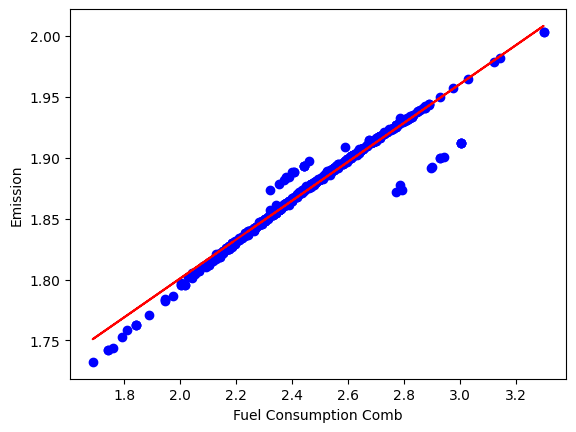

In [27]:
# Reprezentarea grafica a outputului
plt.scatter(X_train[['Fuel Consumption Comb']], y_train[['CO2 Emissions']],  color='blue')
plt.plot(X_train, regr.coef_[0][0]*X_train + regr.intercept_[0], '-r')
plt.xlabel("Fuel Consumption Comb")
plt.ylabel("Emission")

#### Evaluarea modelului
Se compară valorile reale și valorile prezise pentru a calcula acuratețea unui model de regresie.
Măsurile de evaluare oferă un rol cheie în dezvoltarea unui model, deoarece oferă o perspectivă asupra aspectelor ce necesită îmbunătățiri.

Există diferite masuri pentru evaluarea modelului.
**Eroarea absolută medie:** este media valorii absolute a erorilor.
Aceasta este cea mai ușor de înțeles dintre valori, deoarece este doar o eroare medie.

**Media patratului erorilor(MSE):**  este media erorilor pătratice.
Este mai populara decât Eroarea absolută medie, deoarece accentul este orientat mai mult către erori mari.
Acest lucru se datorează faptului că termenul pătrat crește exponențial erorile mai mari în comparație cu cele mai mici.

**Root Mean Squared Error (RMSE).** Este radicalul mediei patratului erorilor.

**R-pătrat** nu este o eroare, ci mai degrabă o măsură populară pentru a măsura performanța modelului de regresie.
Reprezintă cât de aproape sunt punctele observate de linia de regresie ajustată.
Cu cât valoarea lui R pătrat este mai mare, cu atât modelul se potrivește mai bine cu datele dvs.
Cel mai bun scor posibil este 1,0 și poate fi negativ (deoarece modelul poate fi arbitrar mai rău).



In [28]:
# Make predictions on the test set
y_hat = regr.predict(X_test)

In [29]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculăm metricile o singură dată
mae = mean_absolute_error(y_test, y_hat)
mse = mean_squared_error(y_test, y_hat)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_hat)

# Afișare aliniată cu f-strings
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.3f}")

MAE:  0.0035
MSE:  0.0001
RMSE: 0.0074
R²:   0.963


**INTERPRETARE**
Modelul este de o calitate foarte buna, deoarece valoarea lui R2 este peste 0.9.
RMSE il putem folosi pentru compararea mai multor modele, in cazul in care se estimeaza mai multe si dorim sa il determinam pe cel mai bun.

### Exercitiu
Estimati un model de regresie simplu si calculati indicatorii de evaluare a modelului in care sa folositi ca si variabila input: 'Engine Size (L)'.  



# Regresia liniara multipla

***Crearea seturilor de date de antrenare și de testare***

In [30]:
import numpy as np

# Adăugarea unor coloane noi logaritmate
cdf['Cylinders_log'] = np.log1p(cdf['Cylinders'])
cdf['Engine_Size_log'] = np.log1p(cdf['Engine Size (L)'])

# Vizualizarea primelor rânduri
cdf.head()

/tmp/ipykernel_2490/3690390466.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_2490/3690390466.py:5: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,Engine Size (L),Cylinders,Fuel Consumption Comb,CO2 Emissions,Cylinders_log,Engine_Size_log
0,1.5,4,2.104134,1.812210,1.609438,0.916291
1,1.5,4,2.128232,1.816987,1.609438,0.916291
2,1.5,4,2.174752,1.825195,1.609438,0.916291
3,3.5,6,2.501436,1.883419,1.945910,1.504077
4,3.0,6,2.595255,1.898632,1.945910,1.386294


In [31]:
X = np.asanyarray(cdf[['Engine_Size_log','Cylinders_log','Fuel Consumption Comb']])
y = np.asanyarray(cdf[['CO2 Emissions']])

random_seed = 50

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed)

In [32]:
from sklearn import linear_model
regr = linear_model.LinearRegression()

regr.fit (X_train, y_train)

# Afisarea coeficientilor
print ('Coefficientii estimati: ', regr.coef_)

Coefficientii estimati:  [[-0.00438055  0.006681    0.15918816]]


In [34]:
# Calculați valorile t și p-value pentru coeficientul de regresie

from scipy import stats

# Coeficientul de regresie
coef = regr.coef_

# Intercept-ul
intercept = regr.intercept_

# Numărul de observatii
n = len(y_train)

# Numărul de caracteristici (în cazul regresiei liniare simple, este 1)
p = 3

# Calculează eroarea standard a estimatorului coeficientului de regresie
stderr = np.sqrt(((y_train - regr.predict(X_train)) ** 2).sum() / (n - p - 1))

# Calculați statisticile t
t_statistic = coef / (stderr / np.sqrt(((X_train - X_train.mean()) ** 2).sum()))

# Calculează valorile p pentru testele t
p_value = 2 * (1 - stats.t.cdf(np.abs(t_statistic), df=n-p-1))

# Afișați valorile parametrii estimati, t-statistic și p-value

print ('Coefficient: ', regr.coef_)
print ('Intercept: ',regr.intercept_)
print("T-statistic pentru coeficient:", t_statistic)
print("P-value pentru coeficient:", p_value)

Coefficient:  [[-0.00438055  0.006681    0.15918816]]
Intercept:  [1.47651421]
T-statistic pentru coeficient: [[-12.42482833  18.94974214 451.51542807]]
P-value pentru coeficient: [[0. 0. 0.]]


In [35]:
import statsmodels.api as sm

# Adăugăm o coloană de 1 pentru termenul liber (intercept)
X_sm = sm.add_constant(X_train)

# Antrenăm modelul OLS (Ordinary Least Squares)
model = sm.OLS(y_train, X_sm).fit()

# Afișăm tabelul statistic complet
print(model.summary())

# Sau accesăm direct valorile specifice sub formă de vectori:
print("Coeficienți (cu intercept):", model.params)
print("T-statistics:", model.tvalues)
print("P-values:", model.pvalues)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.957
Method:                 Least Squares   F-statistic:                     4910.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:01:47   Log-Likelihood:                 2254.6
No. Observations:                 666   AIC:                            -4501.
Df Residuals:                     662   BIC:                            -4483.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.4765      0.004    364.984      0.0

**INTERPRETARE:**
Toti coeficientii sunt semnificativi pentru un nivel de semnificatie de 0.1.
Coeficientul corespunzator variabilei Engine Size este negativ ceea ce inseamna ca aceasta variabila este invers corelata cu Emisiile de CO2.
Numarul de cilindrii si Consumul de Combustibil combinat, influenteaza in mod direct Emisiile de CO2.

### Parametrii modelului liniar de regresie multipla

Coeficientii și Interceptul sunt parametrii estimati ai modelului de regresie liniara.
Având în vedere că este un model de regresie liniară multiplă cu 3 variabile input, sklearn le poate estima din datele noastre.
Scikit-learn folosește metoda celor mai mici pătrate pentru a rezolva această problemă.

Metoda celor mai mici patrate(OLS): este o metodă de estimare a parametrilor necunoscuți într-un model de regresie liniară.
Aceasta se bazeaza pe minimizarea sumei pătratelor diferențelor dintre variabila dependentă (output, target) și cele prezise de funcția liniară.
Cu alte cuvinte, încearcă să minimizeze suma patratelor erorilor (SSE) sau eroarea pătrată medie (MSE) dintre variabila target (y) și rezultatul nostru prezis (𝑦̂)
pentru setol de date de antrenament.

OLS poate găsi cei mai buni parametri folosind următoarele metode:
- determinarea analitică a parametrilor modelului folosind un sistem de ecuații
- folosind un algoritm de optimizare (Gradient Descent, Stochastic Gradient Descent, Newton’s Method, etc.)

**Calculul statisticii Durbin Whatson**

In [36]:
from statsmodels.stats.stattools import durbin_watson

# calculul reziduurilor
y_pred = regr.predict(X_train)
residuals = y_train - y_pred

# Calcul statistica Durbin-Watson
#dw_statistic = np.sum(np.diff(residuals, axis=0) ** 2) / np.sum(residuals ** 2)
dw = durbin_watson(residuals)

# Regula de decizie
if dw < 1.5:
    result = "Posibilă autocorelare pozitivă a reziduurilor"
elif dw > 2.5:
    result = "Posibilă autocorelare negativa a reziduurilor"
else:
    result = "Fără autocorelare semnificativă (DW ≈ 2)"


print("Durbin-Watson Statistic:", dw)
print("Result:", result)

Durbin-Watson Statistic: [1.98291578]
Result: Fără autocorelare semnificativă (DW ≈ 2)


## Predictie

In [45]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generăm predicțiile pe setul de testare curent
y_hat = regr.predict(X_test)

# Calculăm metricile o singură dată
mae = mean_absolute_error(y_test, y_hat)
mse = mean_squared_error(y_test, y_hat)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_hat)

# Afișare aliniată cu f-strings
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.3f}")

MAE:  0.0038
MSE:  0.0001
RMSE: 0.0084
R²:   0.950


**INTERPRETARE:**
Deoarece R2 este apropiat de valoarea 1, modelul estimat este foarte bun.
Deoarece RMSE este la fel de mic ca al modelului simplu de regresie estimat anterior

*Varianța explicata*
Fie 𝑦̂ targetul estimat, y targetul corespunzător (inregistrat) și Var Varianta (pătratul abaterii standard).

Varianța explicată este estimată astfel:
    𝚎𝚡𝚙𝚕𝚊𝚒𝚗𝚎𝚍 𝚅𝚊𝚛𝚒𝚊𝚗𝚌𝚎(𝑦,𝑦̂ )=1−𝑉𝑎𝑟{𝑦−𝑦̂ }𝑉𝑎𝑟{𝑦}

    Cel mai bun scor posibil este 1,0, valorile mai mici sunt mai slabe.

# **Modelul de regresie Lasso**

In [60]:
#Logaritmarea variabilei target: CO2 Emmissions
Fuel_df['CO2 Emissions'] = np.log1p(Fuel_df['CO2 Emissions'])
Fuel_df

,Model (year),Engine Size (L),Cylinders,Fuel Consumption City,Fuel Consumption Hwy,Fuel Consumption Comb,Fuel Consumption City Comb_mpg,CO2 Emissions,CO2 rating,Smog rating,...,Transmission_AV6,Transmission_AV7,Transmission_AV8,Transmission_M5,Transmission_M6,Transmission_M7,Fuel type_D,Fuel type_E,Fuel type_X,Fuel type_Z
0,2023,1.5,4,7.9,6.3,7.2,39,1.033971,6,7,...,False,True,False,False,False,False,False,False,False,True
1,2023,1.5,4,8.1,6.5,7.4,38,1.035668,6,7,...,False,True,False,False,False,False,False,False,False,True
2,2023,1.5,4,8.9,6.5,7.8,36,1.038578,6,6,...,False,False,False,False,True,False,False,False,False,True
3,2023,3.5,6,12.6,9.4,11.2,25,1.058977,4,5,...,False,False,False,False,False,False,False,False,False,True
4,2023,3.0,6,13.8,11.2,12.4,23,1.064239,4,5,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
828,2023,2.0,4,10.2,7.9,9.2,31,1.048170,5,5,...,False,False,False,False,False,False,False,False,False,True
829,2023,2.0,4,10.3,8.2,9.4,30,1.048928,5,5,...,False,False,False,False,False,False,False,False,False,True
830,2023,2.0,4,11.1,8.7,10.0,28,1.052535,5,7,...,False,False,False,False,False,False,False,False,False,True
831,2023,2.0,4,10.5,8.4,9.6,29,1.050163,5,5,...,False,False,False,False,False,False,False,False,False,True


In [61]:
# Transformarea variabilelor nominale in variabile binare folosind One-hot Encoder

cate_data = ['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel type']

# Verificăm care dintre coloane sunt încă prezente în DataFrame pentru a evita KeyError la rulări repetate
cols_to_encode = [col for col in cate_data if col in Fuel_df.columns]

if cols_to_encode:
    Fuel_df = pd.get_dummies(Fuel_df, columns=cols_to_encode)
    print(f"Coloanele {cols_to_encode} au fost transformate cu succes.")
else:
    print("Coloanele au fost deja transformate anterior.")

Fuel_df.head(3)

Coloanele au fost deja transformate anterior.


,Model (year),Engine Size (L),Cylinders,Fuel Consumption City,Fuel Consumption Hwy,Fuel Consumption Comb,Fuel Consumption City Comb_mpg,CO2 Emissions,CO2 rating,Smog rating,...,Transmission_AV6,Transmission_AV7,Transmission_AV8,Transmission_M5,Transmission_M6,Transmission_M7,Fuel type_D,Fuel type_E,Fuel type_X,Fuel type_Z
0,2023,1.5,4,7.9,6.3,7.2,39,1.033971,6,7,...,False,True,False,False,False,False,False,False,False,True
1,2023,1.5,4,8.1,6.5,7.4,38,1.035668,6,7,...,False,True,False,False,False,False,False,False,False,True
2,2023,1.5,4,8.9,6.5,7.8,36,1.038578,6,6,...,False,False,False,False,True,False,False,False,False,True


# Crearea seturilor de date de antrenare și de testare

In [48]:
# crearea matricilor pentru sklearn:

X = Fuel_df.drop('CO2 Emissions',  axis=1)
y = Fuel_df[['CO2 Emissions']]

In [49]:
print(X.shape)
X.info()

(833, 746)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 833 entries, 0 to 832
Columns: 746 entries, Model (year) to Fuel type_Z
dtypes: bool(737), float64(4), int64(5)
memory usage: 658.2 KB


# Modelul LASSO

In [57]:
import sklearn
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import LassoCV, LassoLarsCV
from sklearn.model_selection import cross_val_score

import eli5
import warnings

In [51]:
# Impartirea setului de date in doua: date de training(70%) si date de test (30%).
random_seed = 50

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=random_seed)

In [52]:
y_train.info()
y_train.shape
y_train


<class 'pandas.core.frame.DataFrame'>
Index: 583 entries, 183 to 688
Data columns (total 1 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CO2 Emissions  583 non-null    float64
dtypes: float64(1)
memory usage: 9.1 KB


,CO2 Emissions
183,1.838686
100,1.891246
582,1.834610
330,1.871996
793,1.891788
...,...
132,1.827827
289,1.886268
109,1.914087
480,1.876926


### **VARIANTA 1**

In [53]:

# Crearea unui model Lasso
# Aplicarea cross validation pentru determinarea celei mai bune valori alphas
model_lasso = LassoCV(alphas = [1, 0.1, 0.01, 0.001, 0.0005], cv=5, random_state=0).fit(X_train, y_train)
print(f"Lasso cv score : {model_lasso.score(X_train, y_train)}")
print(f"Parameters : {model_lasso.get_params}")
print(f"Selected alpha : {model_lasso.alpha_}")

# Cele mai importante variabile (features)
eli5.show_weights(model_lasso, top=-1, feature_names = X_train.columns.tolist())

Lasso cv score : 0.9802232150397927
Parameters : <bound method BaseEstimator.get_params of LassoCV(alphas=[1, 0.1, 0.01, 0.001, 0.0005], cv=5, random_state=0)>
Selected alpha : 0.0005


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:1664: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



Weight?,Feature
+1.986,<BIAS>
+0.001,Cylinders
+0.001,Fuel Consumption Hwy
-0.001,Smog rating
-0.001,Fuel type_E
-0.003,Fuel Consumption City Comb_mpg
-0.009,CO2 rating


**Erorile și problemele identificate:**

**1. Evaluarea scorului pe datele de antrenament (X_train):**
model_lasso.score(X_train, y_train) îți arată scorul $R^2$ pe setul de antrenare, nu scorul obținut din Validarea Crucișată (Cross-Validation) sau pe setul de testare.

**2. Lipsa Scalării Datelor (esențială pentru Lasso):** Lasso penalizează mărimea coeficienților ($L_1$ norm). Dacă variabilele din X_train au scări diferite (de exemplu, vârsta între 18-80 și salariul între 2000-100000), Lasso va penaliza incorect variabilele cu scări mari. Este obligatoriu să standardizezi datele (StandardScaler) înainte de a aplica Lasso.

**3. Grila de alphas:** Deși poți specifica o listă manuală de alphas, este adesea recomandat să lași LassoCV să genereze automat o cale optimă de alphas (n_alphas=100) sau să folosești o scară logaritmică generată cu np.logspace.

### **VARIANTA 2**

In [56]:
import eli5
import numpy as np
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Scalarea datelor
# Scalarea este obligatorie pentru ca penalizarea L1 să funcționeze corect
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Crearea și antrenarea modelului LassoCV
# Poți folosi alphas customizate sau lăsa n_alphas=100 pentru căutare automată
model_lasso = LassoCV(
    alphas=[1.0, 0.1, 0.01, 0.001, 0.0005], cv=5, random_state=0
).fit(X_train_scaled, y_train)

# 3. Afișarea rezultatelor corecte
print(
    f"R^2 pe setul de antrenare : {model_lasso.score(X_train_scaled, y_train):.4f}"
)

# Dacă ai set de test (X_test, y_test), evaluează generalizarea:
if "X_test" in locals() and "y_test" in locals():
    print(
        f"R^2 pe setul de testare  : {model_lasso.score(X_test_scaled, y_test):.4f}"
    )

# MSE mediu minim obținut în Cross-Validation
best_cv_mse = np.mean(
    model_lasso.mse_path_[np.where(model_lasso.alphas_ == model_lasso.alpha_)]
)
print(f"Cel mai bun MSE în CV    : {best_cv_mse:.4f}")

# Parametrii modelului (corectat cu paranteze ())
print(f"Alpha selectat (best)    : {model_lasso.alpha_}")
print(f"Parametrii modelului     :\n{model_lasso.get_params()}")

# 4. Afișarea importanței variabilelor cu ELI5
eli5.show_weights(
    model_lasso, top=-1, feature_names=X_train.columns.tolist()
)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:1664: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



R^2 pe setul de antrenare : 0.9967
R^2 pe setul de testare  : 0.9969
Cel mai bun MSE în CV    : 0.0000
Alpha selectat (best)    : 0.0005
Parametrii modelului     :
{'alphas': [1.0, 0.1, 0.01, 0.001, 0.0005], 'copy_X': True, 'cv': 5, 'eps': 0.001, 'fit_intercept': True, 'max_iter': 1000, 'n_alphas': 100, 'n_jobs': None, 'positive': False, 'precompute': 'auto', 'random_state': 0, 'selection': 'cyclic', 'tol': 0.0001, 'verbose': False}


Weight?,Feature
+1.875,<BIAS>
+0.009,Fuel Consumption Comb
+0.003,Fuel Consumption City
+0.002,Fuel type_D
+0.002,Fuel Consumption Hwy
+0.001,Engine Size (L)
+0.000,Model_AMG E 63 4MATIC+ All-Terrain Wagon
+0.000,Cylinders
-0.000,Smog rating
-0.004,CO2 rating


### **VARIANTA 3**

In [55]:
import eli5
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# 1. Scalarea datelor (obligatorie pentru ca Lasso să evalueze corect coeficienții)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 2. Crearea LassoCV fără a specifica parametrul `alphas`
# n_alphas=100 (implicit) face ca LassoCV să genereze automat calea optimă de 100 de valori alpha
model_lasso = LassoCV(n_alphas=100, cv=5, random_state=0).fit(
    X_train_scaled, y_train
)

# 3. Afișarea alpha-ului găsit automat și performanța modelului
print(f"Alpha selectat automat de LassoCV : {model_lasso.alpha_:.6f}")
print(
    f"R^2 pe setul de antrenare        : {model_lasso.score(X_train_scaled, y_train):.4f}"
)

if "X_test" in locals() and "y_test" in locals():
    X_test_scaled = scaler.transform(X_test)
    print(
        f"R^2 pe setul de testare         : {model_lasso.score(X_test_scaled, y_test):.4f}"
    )

# 4. Varianta A: Afișarea primilor 10 parametri cu ELI5
# Parametrul top=10 oprește tabelul la primele 10 cele mai importante variabile
display(
    eli5.show_weights(
        model_lasso, top=10, feature_names=X_train.columns.tolist()
    )
)

# 5. Varianta B: Extragerea primilor 10 parametri sub formă de DataFrame Pandas (fără ELI5)
top10_df = (
    pd.DataFrame(
        {
            "Feature": X_train.columns,
            "Coeficient": model_lasso.coef_,
            "Importanta_Absoluta": np.abs(model_lasso.coef_),
        }
    )
    .query("Coeficient != 0")  # elimină caracteristicile anulate de Lasso
    .sort_values(by="Importanta_Absoluta", ascending=False)
    .head(10)
    .drop(columns=["Importanta_Absoluta"])
)

print("\nTop 10 parametri semnificativi (Pandas DataFrame):")
print(top10_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:1664: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



Alpha selectat automat de LassoCV : 0.000038
R^2 pe setul de antrenare        : 0.9996
R^2 pe setul de testare         : 0.9987



Top 10 parametri semnificativi (Pandas DataFrame):
                                 Feature  Coeficient
          Fuel Consumption City Comb_mpg   -0.022828
                   Fuel Consumption City    0.010936
                             Fuel type_E   -0.007501
                    Fuel Consumption Hwy    0.006114
                             Fuel type_D    0.003064
                   Fuel Consumption Comb    0.001731
                            Make_Bugatti   -0.000496
Model_AMG E 63 4MATIC+ All-Terrain Wagon    0.000478
                  Model_Chiron Pur Sport   -0.000346
                Model_Chiron Super Sport   -0.000346


In [62]:
# Predictie folosind modelul Lasso antrenat anterior
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ne asigurăm că datele de test sunt scalate
X_test_scaled = scaler.transform(X_test)

# Generăm predicțiile corecte (y_hat) care să aibă aceeași dimensiune ca y_test (250 eșantioane)
y_hat = model_lasso.predict(X_test_scaled)

# Calculăm metricile
mae = mean_absolute_error(y_test, y_hat)
mse = mean_squared_error(y_test, y_hat)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_hat)

# Afișare aliniată cu f-strings
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.3f}")

MAE:  0.0017
MSE:  0.0000
RMSE: 0.0021
R²:   0.997


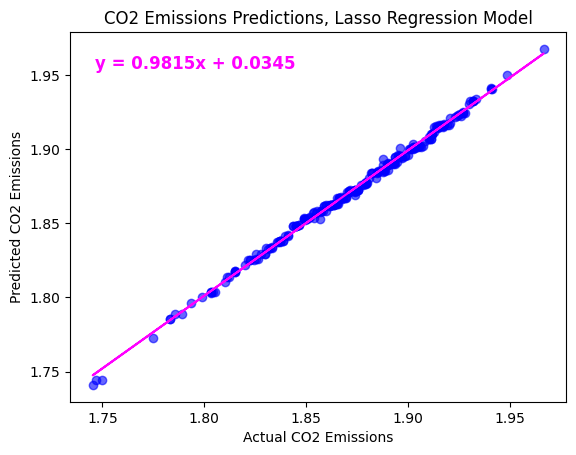

In [63]:
import matplotlib.pyplot as plt
import numpy as np

# Extragem valorile din DataFrame sub formă de vector 1D
y_test_values = y_test['CO2 Emissions'].values

# Graficul de împrăștiere (Scatter plot)
plt.scatter(y_test_values, y_hat, color='blue', alpha=0.6)
plt.xlabel('Actual CO2 Emissions')
plt.ylabel('Predicted CO2 Emissions')
plt.title('CO2 Emissions Predictions, Lasso Regression Model')

# Dreapta de regresie
z = np.polyfit(y_test_values, y_hat, 1)
p = np.poly1d(z)
plt.plot(y_test_values, p(y_test_values), color='magenta')

# Ecuația de regresie
trendline_eq = f"y = {round(z[0], 4)}x + {round(z[1], 4)}"
plt.text(0.05, 0.90, trendline_eq, transform=plt.gca().transAxes, color='magenta', fontsize=12, fontweight='bold')

plt.show()

In [64]:
# Transformarea valorilor previzionate in valori reale de CO2 prin ridicarea la puterea e
lasso_preds = np.expm1(y_pred)
lasso_preds

array([[5.58319656],
       [5.27623926],
       [5.21415494],
       [5.64646369],
       [5.85447296],
       [5.42225352],
       [5.63444893],
       [5.76266706],
       [5.61121618],
       [5.43177084],
       [5.60233126],
       [5.63906741],
       [5.24058965],
       [5.51178159],
       [5.76966091],
       [4.83766255],
       [5.46641391],
       [5.46626887],
       [5.94522774],
       [5.44121434],
       [5.25878122],
       [5.3123008 ],
       [5.28693406],
       [5.333054  ],
       [5.26967959],
       [5.68057944],
       [5.19843751],
       [5.54301181],
       [5.56152846],
       [5.22937445],
       [5.14877572],
       [5.47550739],
       [5.73480143],
       [5.44121434],
       [5.54055516],
       [5.16350125],
       [5.5687815 ],
       [5.14386685],
       [5.88130339],
       [5.50281284],
       [5.46911427],
       [6.00173547],
       [5.77654115],
       [5.48070789],
       [5.55567368],
       [5.91485589],
       [5.64953199],
       [5.598

In [66]:
# Se exporta solutia in format csv folosind predictiile corecte pe setul de test

# 1. Ne asigurăm că prezicem pe setul de testare scalat folosind modelul Lasso
y_hat_lasso = model_lasso.predict(X_test_scaled)

# 2. Convertim înapoi din log-space în valori reale de CO2
lasso_test_preds_real = np.expm1(y_hat_lasso)

# 3. Exportăm în DataFrame aplatizând vectorul cu .ravel()
solution = pd.DataFrame({'id': y_test.index, 'CO2 Emissions': lasso_test_preds_real.ravel()})
solution.to_csv("submission.csv", index = False)
print("Soluția Lasso a fost exportată cu succes în 'submission.csv'!")

Soluția Lasso a fost exportată cu succes în 'submission.csv'!


# **Crearea unui model Ridge**

In [67]:
import eli5
import numpy as np
import pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

# 1. Scalarea datelor (obligatorie pentru ca penalizarea L2 din Ridge să funcționeze corect)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 2. Definitivarea grilei de căutare pentru alpha și antrenarea modelului RidgeCV
# Pentru Ridge, este recomandat să transmitem o grilă logaritmică (ex: de la 0.001 la 1000)
#Comanda np.logspace(-3, 3, 100) generează un tablou de 100 de numere distribuite uniform pe o scară logaritmică între $10^{-3}$ (adică 0.001) și $10^3$ (adică 1000).
#Detalierea parametrilor:
#    -3 (start): Exponentul limitei inferioare, adică $10^{-3} = 0.001$.
#     3 (stop): Exponentul limitei superioare, adică $10^3 = 1000$.
#     100 (num): Numărul total de valori generate în acest interval.

alphas = np.logspace(-3, 3, 100)
model_ridge = RidgeCV(alphas=alphas, cv=5).fit(X_train_scaled, y_train)

# 3. Afișarea alpha-ului optim selectat și a scorurilor R^2
print(f"Alpha selectat automat de RidgeCV : {model_ridge.alpha_:.6f}")
print(
    f"R^2 pe setul de antrenare        : {model_ridge.score(X_train_scaled, y_train):.4f}"
)

if "X_test" in locals() and "y_test" in locals():
    X_test_scaled = scaler.transform(X_test)
    print(
        f"R^2 pe setul de testare         : {model_ridge.score(X_test_scaled, y_test):.4f}"
    )

# 4. Varianta A: Afișarea primilor 10 parametri cu ELI5
display(
    eli5.show_weights(
        model_ridge, top=10, feature_names=X_train.columns.tolist()
    )
)

# 5. Varianta B: Extragerea primilor 10 parametri într-un DataFrame Pandas
top10_ridge_df = (
    pd.DataFrame(
        {
            "Feature": X_train.columns,
            "Coeficient": model_ridge.coef_,
            "Importanta_Absoluta": np.abs(model_ridge.coef_),
        }
    )
    .sort_values(by="Importanta_Absoluta", ascending=False)
    .head(10)
    .drop(columns=["Importanta_Absoluta"])
)

print("\nTop 10 parametri semnificativi (Pandas DataFrame):")
print(top10_ridge_df.to_string(index=False))

Alpha selectat automat de RidgeCV : 0.001000
R^2 pe setul de antrenare        : 0.9999
R^2 pe setul de testare         : 0.9969



Top 10 parametri semnificativi (Pandas DataFrame):
                       Feature  Coeficient
         Fuel Consumption City    0.018519
Fuel Consumption City Comb_mpg   -0.016938
          Fuel Consumption Hwy    0.009525
                   Fuel type_E   -0.008026
         Fuel Consumption Comb   -0.003647
                   Fuel type_D    0.003226
                     Cylinders    0.001834
               Engine Size (L)   -0.001814
                  Make_Bugatti   -0.001074
      Model_Chiron Super Sport   -0.000820


In [ ]:
# Predictie folosind modelul Ridge

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ne asigurăm că datele de test sunt scalate
X_test_scaled = scaler.transform(X_test)

# Generăm predicțiile corecte (y_hat) care să aibă aceeași dimensiune ca y_test (250 eșantioane)
y_hat = model_lasso.predict(X_test_scaled)

# Calculăm metricile
mae = mean_absolute_error(y_test, y_hat)
mse = mean_squared_error(y_test, y_hat)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_hat)

# Afișare aliniată cu f-strings
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.3f}")

MAE:  0.0078
MSE:  0.0001
RMSE: 0.0104
R²:   0.998


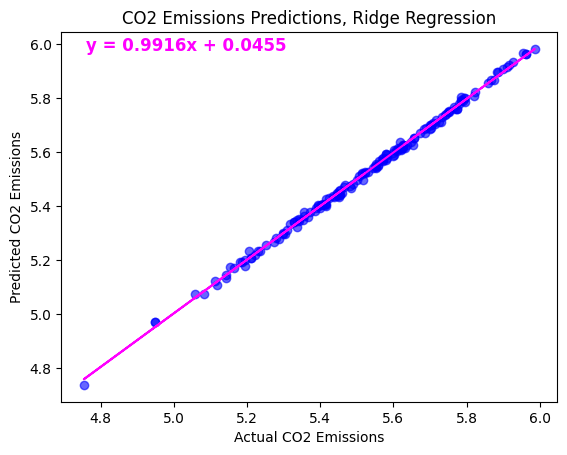

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ne asigurăm că ambele variabile sunt vectori 1D plați
y_test_1d = y_test['CO2 Emissions'].values.ravel()
y_pred_1d = y_pred.ravel()

plt.scatter(y_test_1d, y_pred_1d, color='blue', alpha=0.6)
plt.xlabel('Actual CO2 Emissions')
plt.ylabel('Predicted CO2 Emissions')
plt.title('CO2 Emissions Predictions, Ridge Regression')

# Dreapta de regresie
z = np.polyfit(y_test_1d, y_pred_1d, 1)
p = np.poly1d(z)
plt.plot(y_test_1d, p(y_test_1d), color='magenta')

# Ecuatia de regresie
trendline_eq = f"y = {round(z[0], 4)}x + {round(z[1], 4)}"
plt.text(0.05, 0.95, trendline_eq, transform=plt.gca().transAxes, color='magenta', fontsize=12, fontweight='bold')
plt.show()

In [ ]:
# Previziune
ridge_preds = ridge_cv_model.predict(X_test)
ridge_preds

array([5.52698658, 5.36085648, 5.42663124, 5.29621639, 5.48047539,
       5.39117023, 5.28048735, 5.21989264, 5.43719381, 5.37731785,
       5.43726291, 5.62505062, 5.26718717, 5.4463207 , 5.23272925,
       5.10838347, 5.39999553, 5.56825143, 5.37935728, 5.4979075 ,
       5.54141741, 5.40294947, 5.40819327, 5.80877791, 5.19878597,
       5.9644781 , 5.58982175, 5.43444056, 5.93198602, 5.57108522,
       5.23366057, 5.12414661, 5.71063567, 5.76716652, 5.74873716,
       5.7583922 , 5.49691785, 5.34353539, 5.61125731, 5.40403253,
       5.17677584, 5.45787341, 5.52496404, 5.57981367, 5.43040575,
       5.96481178, 5.61448584, 5.34908864, 5.75825498, 5.40109971,
       5.80268767, 5.3824704 , 5.89576935, 5.55289967, 5.34091782,
       5.31059313, 5.29864353, 5.39114109, 5.71291688, 5.62340138,
       5.13488835, 5.69908919, 5.59272586, 5.73718103, 5.89691015,
       5.91387024, 4.73820019, 5.40936119, 5.62455352, 5.54223604,
       5.60728344, 5.29771421, 5.44542661, 5.57140758, 5.78805

In [ ]:
# Transformarea valorilor previzionate in valori reale de CO2 prin ridicarea la puterea e
ridge_preds = np.expm1(ridge_preds)
ridge_preds

array([250.3852396 , 211.90721819, 226.38195785, 198.58024587,
       238.96075421, 218.46005429, 195.46559919, 183.91433124,
       228.79642617, 215.44096915, 228.81230525, 276.28632001,
       192.86987273, 230.90335299, 186.3033047 , 164.40276035,
       220.40542585, 260.97561497, 215.8828366 , 243.18044893,
       254.03923891, 221.06041281, 222.22791033, 332.21166286,
       180.05230619, 388.34977368, 266.68790122, 228.16460756,
       375.90230796, 261.71905276, 186.47782402, 167.03068491,
       301.06302031, 318.63078037, 312.79413687, 315.83850636,
       242.93891649, 208.25118826, 272.48788086, 221.30104736,
       176.11085573, 233.59799871, 249.87731661, 264.02222017,
       227.24183528, 388.47971253, 273.37227246, 209.41644633,
       315.79503178, 220.6500332 , 330.18848899, 216.55907024,
       362.49638523, 256.98454307, 207.70417459, 201.47028382,
       199.06524393, 218.45365974, 301.7528757 , 275.82938441,
       168.84535618, 297.59531372, 267.4664241 , 309.18

In [ ]:
# Se exporta solutia in format csv prin aplatizarea predicțiilor într-un vector 1D
solution = pd.DataFrame({'id': y_test.index, 'CO2 Emissions': ridge_preds.ravel()})
solution.to_csv("submission_ridge.csv", index = False)
print("Soluția pentru Ridge a fost exportată cu succes în 'submission_ridge.csv'!")

Soluția pentru Ridge a fost exportată cu succes în 'submission_ridge.csv'!


In [ ]:
y_test.index

Int64Index([451, 310, 664, 306, 682, 738,  31, 843, 432, 150,
            ...
            253, 516,  18, 596, 156, 495, 644,  50, 821, 406],
           dtype='int64', length=172)